In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
size = 256

d1 = 20
alpha1 = 0.2
phi1 = np.pi/3

d2 = 40
alpha2 = 0.05
phi2 = np.pi/3

R = np.random.choice([-1,1], size = size)
echo1 = (alpha1 * np.exp(1j * phi1))*np.append(np.append(np.zeros(d1), R), np.zeros(size + d2 - d1 - len(R)))
echo2 = (alpha2 * np.exp(1j * phi2))*np.append(np.zeros(d2), R)
V = echo1 + echo2

C_2echos = np.correlate(V, R, mode = 'full')
lag = np.arange(len(C_2echos)) - len(R) + 1
magnitude_C_2echos = np.abs(C_2echos)
peaks = []

for i in range(1, len(magnitude_C_2echos)-1):
    if magnitude_C_2echos[i] > 20:
        if magnitude_C_2echos[i] > magnitude_C_2echos[i-1] and magnitude_C_2echos[i] > magnitude_C_2echos[i+1]:
            peaks.append(i)
print(f"Detected peaks at lags: {lag[peaks]}")

e_1 = np.argmax(np.abs(C_2echos)) - (len(R) -1)
print(f"Estimated delay: {e_1}, Actual delay: {d1}")

max_C_1, idx_C_1 = np.max(np.abs(C_2echos)), np.argmax(np.abs(C_2echos))
alpha_hat_1 = max_C_1 / np.sum(np.abs(R)**2)
phi_hat_1 = np.arctan2(C_2echos[idx_C_1].imag, C_2echos[idx_C_1].real)        
print(f"Estimated amplitude: {alpha_hat_1}")
print(f"Estimated phase: {phi_hat_1}")


Detected peaks at lags: [20 40]
Estimated delay: 20, Actual delay: 20
Estimated amplitude: 0.20820312500000002
Estimated phase: 1.0471975511965974


In [5]:
W = V - (alpha_hat_1 * np.exp(1j * phi_hat_1)) *np.append(np.append(np.zeros(e_1), R), np.zeros(size + d2 - e_1 - len(R)))
C_W = np.correlate(W, R, mode = 'full')

e_2 = np.argmax(np.abs(C_W)) - (len(R) -1)
print(f"Estimated delay: {e_2}, Actual delay: {d2}")

max_C_2, idx_C_2 = np.max(np.abs(C_W)), np.argmax(np.abs(C_W))
alpha_hat_2 = max_C_2 / np.sum(np.abs(R)**2)
phi_hat_2 = np.arctan2(C_W[idx_C_2].imag, C_W[idx_C_2].real)        
print(f"Estimated amplitude: {alpha_hat_2}")
print(f"Estimated phase: {phi_hat_2}")


Estimated delay: 40, Actual delay: 40
Estimated amplitude: 0.04865417480468751
Estimated phase: 1.0471975511965979


Text(0, 0.5, 'Magnitude')

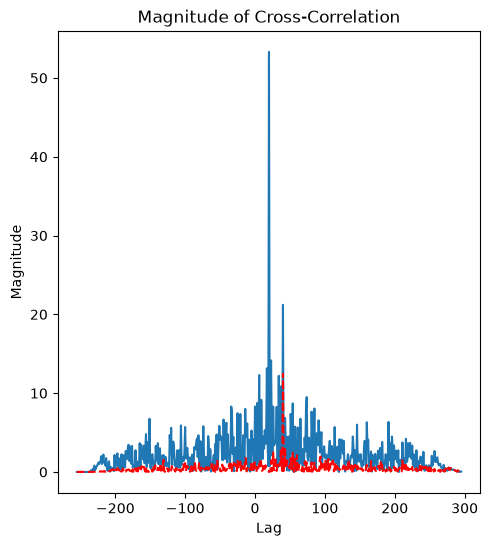

In [6]:

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(lag, np.abs(C_2echos))
plt.plot(lag, np.abs(C_W), 'r--')
plt.title('Magnitude of Cross-Correlation')
plt.xlabel('Lag')
plt.ylabel('Magnitude') 

In [7]:
W2 = V - (alpha_hat_2 * np.exp(1j * phi_hat_2)) * np.append(np.zeros(e_2), R)
C_W2 = np.correlate(W2, R, mode = 'full')

e_1_v2 = np.argmax(np.abs(C_W2)) - (len(R) -1)
print(f"Estimated delay: {e_1_v2}, Actual delay: {d1}")

max_C_1_v2, idx_C_1_v2 = np.max(np.abs(C_W2)), np.argmax(np.abs(C_W2))
alpha_hat_1_v2 = max_C_1_v2 / np.sum(np.abs(R)**2)
phi_hat_1_v2 = np.arctan2(C_W2[idx_C_1_v2].imag, C_W2[idx_C_1_v2].real)        
print(f"Estimated amplitude: {alpha_hat_1_v2}")
print(f"Estimated phase: {phi_hat_1_v2}")


Estimated delay: 20, Actual delay: 20
Estimated amplitude: 0.200220799446106
Estimated phase: 1.0471975511965974
